# Задание 2.1. Классификация сердечных сокращений по ЭКГ

Каждое сокращение — сигнал из 140 точек. Предсказываем класс `prediction` (0–4).
Модель — простая 1D CNN на PyTorch, взвешенная функция потерь против дисбаланса, лучшая эпоха выбирается по macro F1 на val.
Результат — `outputs/task2_1_predictions.csv` со столбцами `heartbeat_id`, `prediction`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42  # чтобы результат повторялся
np.random.seed(SEED)
torch.manual_seed(SEED)

**1. Загрузить данные**

Если ноутбук запущен в репозитории — читаем локальные файлы, иначе (например, в Colab) — скачиваем с GitHub.

In [2]:
repo_root = Path.cwd()
if repo_root.name == 'your-sollution':
    repo_root = repo_root.parent


def dataset_path(filename):
    local = repo_root / 'dataset' / 'task2_1' / filename
    if local.exists():
        return str(local)
    return ('https://github.com/AI-is-out-there/check-your-biomed-datascience-skills-review/'
            f'raw/refs/heads/dev/dataset/task2_1/{filename}')


train = pd.read_csv(dataset_path('train.csv'))
test = pd.read_csv(dataset_path('test_features.csv'))
print('train:', train.shape, ' test_features:', test.shape)
print('Пропусков в train:', train.isna().sum().sum())

train: (4000, 142)  test_features: (1000, 141)
Пропусков в train: 0


**Вывод:** в train 4000 размеченных сокращений: `heartbeat_id`, `prediction` и 140 точек сигнала. В `test_features` 1000 сокращений без метки. Пропусков нет.

**Признаки и классы**

Признаки — 140 точек сигнала `t_000`–`t_139`. Смотрим, сколько примеров в каждом классе.

In [3]:
FEATURES = [c for c in train.columns if c.startswith('t_')]
CLASS_NAMES = ['0 Норма', '1 R-on-T PVC', '2 PVC', '3 SP/EB', '4 UB']

X = train[FEATURES].to_numpy(dtype=np.float32)
y = train['prediction'].to_numpy()
counts = pd.Series(y).value_counts().sort_index()
print(pd.DataFrame({'класс': CLASS_NAMES, 'штук': counts.values, 'доля': (counts / len(y)).round(3).values}))

          класс  штук   доля
0       0 Норма  2335  0.584
1  1 R-on-T PVC  1414  0.354
2         2 PVC    77  0.019
3       3 SP/EB   155  0.039
4          4 UB    19  0.005


**Вывод:** классы сильно несбалансированы: норма (58%) и R-on-T PVC (35%) — это 93% данных, а PVC — 77 штук (1.9%), SP/EB — 155 (3.9%), UB — всего 19 (0.5%). Без борьбы с дисбалансом сеть почти не будет предсказывать классы 2–4.

**Представительные сигналы всех классов**

Тонкие линии — 10 случайных сокращений класса, толстая — среднее по классу.

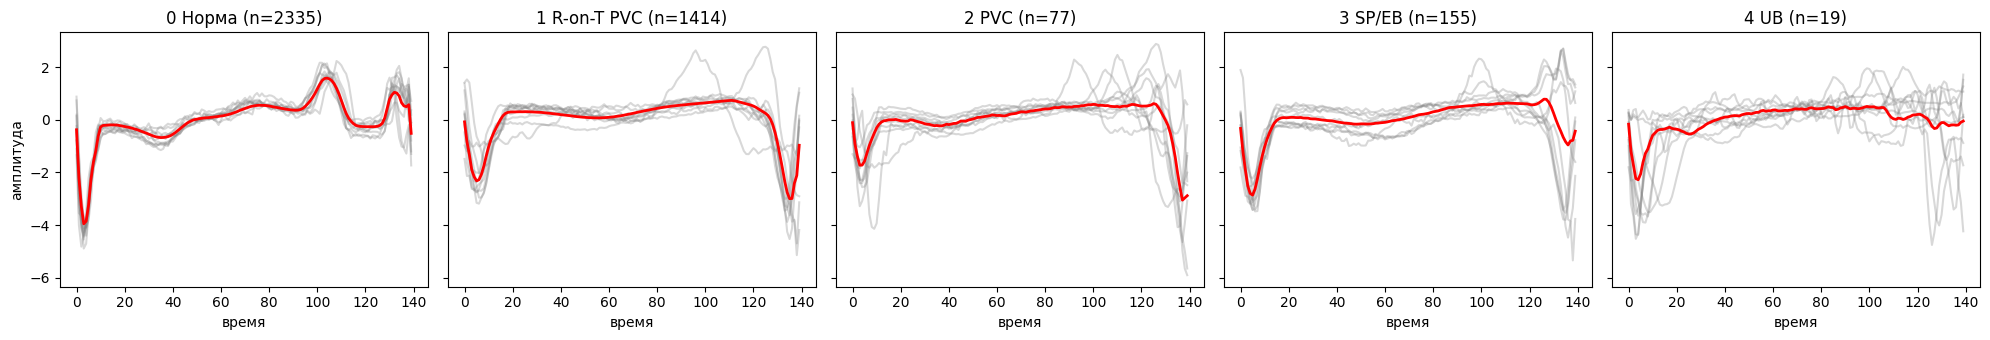

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
rng = np.random.default_rng(SEED)
for k, ax in enumerate(axes):
    signals = X[y == k]
    for s in signals[rng.choice(len(signals), 10, replace=False)]:
        ax.plot(s, color='gray', alpha=0.3)
    ax.plot(signals.mean(axis=0), color='red', lw=2)
    ax.set_title(f'{CLASS_NAMES[k]} (n={len(signals)})')
    ax.set_xlabel('время')
axes[0].set_ylabel('амплитуда')
plt.tight_layout()
plt.show()

**Вывод:** норма хорошо узнаётся — после начального провала есть отчётливый подъём около точки 105. У классов 1, 2 и 3 похожая форма: провал в начале, ровная середина и провал в конце. Отличаются они в основном тем, где и насколько глубоко этот конечный провал. Класс 4 (UB) самый разнородный — его сигналы мало похожи друг на друга, поэтому он будет самым трудным.

**2. Разделить на train / val / test**

Пропорции 60 / 20 / 20, `stratify` сохраняет долю каждого класса во всех частях — это важно для редких классов 2 и 4.

In [5]:
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)
print('train:', len(X_train), ' val:', len(X_val), ' test:', len(X_test))
print('Класс 4 (UB) в train / val / test:', (y_train == 4).sum(), (y_val == 4).sum(), (y_test == 4).sum())

train: 2400  val: 800  test: 800
Класс 4 (UB) в train / val / test: 11 4 4


**Вывод:** 2400 сокращений на обучение, по 800 на val и test. Доли классов одинаковы во всех частях, но класса UB в val и test всего по 4 примера — метрики для него будут очень шумными.

**3. Нормализовать через StandardScaler**

Каждую из 140 точек приводим к среднему 0 и std 1. `fit` — только на train, val и test преобразуем теми же параметрами.

In [6]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)


def to_tensor(a):
    return torch.tensor(a[:, None, :], dtype=torch.float32)  # форма (N, 1 канал, 140 точек)


Xt_train, Xt_val, Xt_test = to_tensor(X_train_s), to_tensor(X_val_s), to_tensor(X_test_s)
yt_train = torch.tensor(y_train, dtype=torch.long)
print('Форма входа сети:', tuple(Xt_train.shape))

Форма входа сети: (2400, 1, 140)


**Вывод:** вход сети — 2400 сигналов, 1 канал, 140 точек. Сигналы в ECG5000 уже почти нормированы, поэтому StandardScaler в основном выравнивает разброс между точками.

**4. Модель: 1D CNN + взвешенная функция потерь**

Три свёрточных слоя ищут характерные формы в сигнале (зубцы, провалы), затем полносвязный слой выдаёт 5 классов.
Карту признаков не усредняем по времени, а разворачиваем (`Flatten`): классы отличаются тем, *где* в сокращении зубец,
и усреднение эту информацию теряет (с `AdaptiveAvgPool1d` из базового ноутбука macro F1 на test был лишь 0.43).

Против дисбаланса — веса классов в `CrossEntropyLoss`: вес = N / (5 · число примеров класса).
Ошибка на редком классе стоит дороже, и сеть не может просто игнорировать его.

In [7]:
model = nn.Sequential(
    nn.Conv1d(1, 16, kernel_size=7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
    nn.Conv1d(16, 32, kernel_size=5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
    nn.Conv1d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
    nn.Flatten(), nn.Dropout(0.2), nn.Linear(64 * 35, 5),  # 140 точек / 2 / 2 = 35
)

class_weights = len(y_train) / (5 * np.bincount(y_train))
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print('Веса классов:', class_weights.round(2))

Веса классов: [ 0.34  0.57 10.21  5.16 43.64]


**Вывод:** ошибка на одном примере UB стоит в 128 раз дороже, чем на норме (43.6 против 0.34), на PVC — в 30 раз. Так редкие классы влияют на обучение наравне с частыми.

**5. Обучение с выбором лучшей эпохи по macro F1 на val**

Macro F1 — среднее F1 по 5 классам, каждый класс весит одинаково. Accuracy тут обманчива: модель, которая всегда говорит «норма», уже даёт 58%.
Учим 40 эпох батчами по 64 и запоминаем веса эпохи с лучшим macro F1 на val.

In [8]:
def evaluate(Xt, y_true):
    model.eval()
    with torch.no_grad():
        logits = model(Xt)
    loss = criterion(logits, torch.tensor(y_true, dtype=torch.long)).item()
    pred = logits.argmax(dim=1).numpy()
    return loss, f1_score(y_true, pred, average='macro'), pred


EPOCHS = 40
history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}
best_f1, best_epoch, best_state = -1, 0, None

for epoch in range(EPOCHS):
    model.train()
    for idx in torch.randperm(len(Xt_train)).split(64):
        optimizer.zero_grad()
        loss = criterion(model(Xt_train[idx]), yt_train[idx])
        loss.backward()
        optimizer.step()

    tr_loss, tr_f1, _ = evaluate(Xt_train, y_train)
    va_loss, va_f1, _ = evaluate(Xt_val, y_val)
    for key, val in zip(history, [tr_loss, va_loss, tr_f1, va_f1]):
        history[key].append(val)
    if va_f1 > best_f1:
        best_f1, best_epoch = va_f1, epoch + 1
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
print(f'Лучшая эпоха: {best_epoch}, macro F1 на val: {best_f1:.3f}')

Лучшая эпоха: 25, macro F1 на val: 0.672


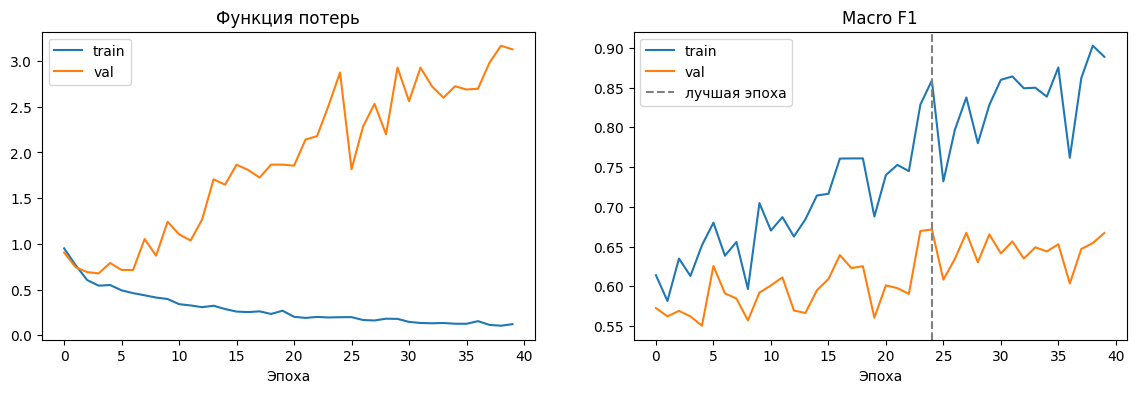

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(history['train_loss'], label='train')
ax1.plot(history['val_loss'], label='val')
ax1.set_title('Функция потерь')
ax2.plot(history['train_f1'], label='train')
ax2.plot(history['val_f1'], label='val')
ax2.axvline(best_epoch - 1, color='gray', ls='--', label='лучшая эпоха')
ax2.set_title('Macro F1')
for ax in (ax1, ax2):
    ax.set_xlabel('Эпоха')
    ax.legend()
plt.show()

**Вывод:** loss на train стабильно падает, а на val начинает расти уже с ~5-й эпохи: из-за больших весов сеть становится слишком уверенной и сильно штрафуется за ошибки на редких классах. При этом macro F1 на val продолжает расти примерно до 25-й эпохи (0.67) — поэтому выбираем модель по macro F1, а не по loss. Разрыв train F1 ~0.85–0.9 и val F1 ~0.65 показывает переобучение на редких классах.

**6. Оценка на отложенном test**

Test не участвовал ни в обучении, ни в выборе эпохи — это честная оценка.

In [10]:
_, test_f1, test_pred = evaluate(Xt_test, y_test)
print(f'Accuracy: {accuracy_score(y_test, test_pred):.3f}   Macro F1: {test_f1:.3f}\n')
print(classification_report(y_test, test_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))

Accuracy: 0.932   Macro F1: 0.581

              precision    recall  f1-score   support

     0 Норма      0.985     0.979     0.982       467
1 R-on-T PVC      0.927     0.940     0.933       283
       2 PVC      0.423     0.733     0.537        15
     3 SP/EB      0.545     0.387     0.453        31
        4 UB      0.000     0.000     0.000         4

    accuracy                          0.932       800
   macro avg      0.576     0.608     0.581       800
weighted avg      0.932     0.932     0.931       800



**Вывод:** Accuracy 0.93, macro F1 0.58. Норма (F1 0.98) и R-on-T PVC (0.93) распознаются отлично. PVC нашли 11 из 15 (recall 0.73), но с ложными срабатываниями (precision 0.42). SP/EB — только 12 из 31. UB — ни одного из 4. Macro F1 на test ниже, чем на val (0.67): редких примеров мало, и одна-две ошибки сильно меняют метрику.

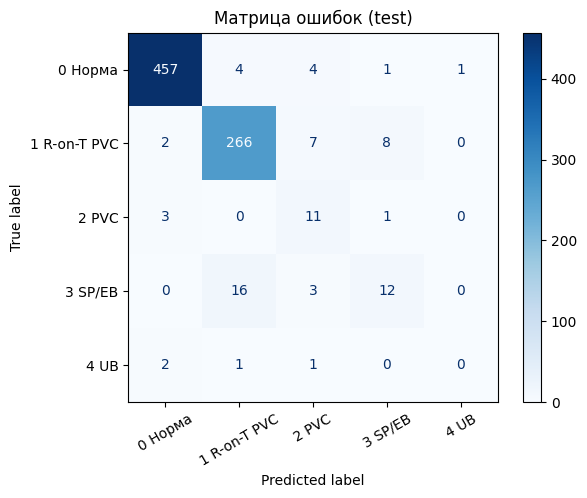

In [11]:
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=CLASS_NAMES).plot(cmap='Blues', xticks_rotation=30)
plt.title('Матрица ошибок (test)')
plt.show()

**7. Вывод по ошибкам:** чаще всего путаются SP/EB → R-on-T PVC (16 из 31) и обратно (8): у этих классов почти одинаковая форма с провалами в начале и в конце, и на 155 примерах сеть не выучила тонкую разницу. R-on-T PVC иногда принимается за PVC (7) — снова похожая морфология. Все 4 UB ушли в другие классы: 11 примеров в train слишком мало, а сигналы UB к тому же очень разнородны. Норма почти не путается — у неё своя форма. Итого ошибки сосредоточены там, где классы похожи по форме и при этом редкие.

**Предсказания для test_features.csv и сохранение**

Масштабируем тем же scaler, что обучен на train, и берём класс с максимальным выходом сети.

In [12]:
X_final = to_tensor(scaler.transform(test[FEATURES].to_numpy(dtype=np.float32)))
model.eval()
with torch.no_grad():
    final_pred = model(X_final).argmax(dim=1).numpy()

submission = pd.DataFrame({'heartbeat_id': test['heartbeat_id'], 'prediction': final_pred.astype(int)})
out_path = repo_root / 'outputs' / 'task2_1_predictions.csv'
out_path.parent.mkdir(exist_ok=True)
submission.to_csv(out_path, index=False)

# Проверяем требования: строка на каждое сокращение, те же id, классы 0–4, без пропусков
assert len(submission) == len(test)
assert submission['heartbeat_id'].equals(test['heartbeat_id'])
assert submission['prediction'].isin(range(5)).all()
assert submission.notna().all().all()
print('Сохранено:', out_path, '| строк:', len(submission))
print(submission['prediction'].value_counts().sort_index())

Сохранено: /Users/krovenmor/projects/UNI/AI_cringe/ai_mega_repo/outputs/task2_1_predictions.csv | строк: 1000
prediction
0    583
1    356
2     25
3     32
4      4
Name: count, dtype: int64


**Вывод:** файл сохранён: 1000 строк, id совпадают с `test_features`, классы 0–4, пропусков нет. Распределение прогнозов (58% норма, 36% R-on-T PVC, остальные классы 0.4–3%) близко к распределению в train.

## Отчёт

**Предобработка.** 4000 сигналов по 140 точек, пропусков нет. Стратифицированное разбиение 60/20/20 (train/val/test). StandardScaler по каждой точке обучен только на train.

**Модель.** 1D CNN: три свёрточных слоя (16, 32, 64 фильтра) с ReLU и MaxPool, затем Flatten, Dropout 0.2 и линейный слой на 5 классов. Adam, lr 1e-3, батч 64, 40 эпох. Flatten вместо усреднения по времени важен: классы отличаются положением зубцов, и с усреднением macro F1 на test был лишь 0.43.

**Дисбаланс.** Классы 2–4 — всего 6% данных (UB — 19 примеров). Используется CrossEntropyLoss с весами N / (5 · n_класса), стратификация при разбиении и выбор эпохи по macro F1 на val (лучшая — 25-я, val macro F1 0.67). Val loss при этом растёт — сеть слишком уверена на редких классах, поэтому ориентируемся на F1.

**Результат (test, 800 сокращений).** Accuracy 0.93, macro F1 0.58. F1 по классам: норма 0.98, R-on-T PVC 0.93, PVC 0.54, SP/EB 0.45, UB 0.

**Ошибки.** Основная путаница — SP/EB ↔ R-on-T PVC и R-on-T PVC → PVC: эти классы похожи по форме (провал в начале и в конце сокращения), а редкие из них представлены слишком малым числом примеров. UB не распознан ни разу: 11 примеров в train и очень разнородные сигналы.

**Улучшения.** Аугментация редких классов (сдвиг, шум, масштаб) или oversampling, focal loss, кросс-валидация вместо одного val (в val всего 4 примера UB, поэтому выбор модели шумный), ранняя остановка и weight decay против переобучения, ансамбль нескольких запусков.